# Figure 3: TMB axis score across cancer types

Compares TMB axis scores between high- and low-TMB tumors across 32 TCGA cancer types,
benchmarked against matched GTEx normal tissue.

In [1]:
import socket, os, sys
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

mpl.rcParams["pdf.fonttype"] = 42

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

WORKING_DIR = f"{BASE_DIR}/analysis/01_axis_analysis/bh"
os.chdir(WORKING_DIR)

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

## Load data

In [30]:
df_gtex = pd.read_parquet(f"{WORKING_DIR}/axis_sample_scores/tcga_gtex_toil/gtex_normal_axis.parquet")
df_axis = pd.read_parquet(f"{WORKING_DIR}/axis_sample_scores/tcga_xena/axis_sample_level.parquet")

## Prepare data

In [31]:
tcga_to_gtex = {
    "BLCA": "Bladder",
    "BRCA": "Breast",
    "CESC": "Cervix Uteri",
    "COAD": "Colon",
    "ESCA": "Esophagus",
    "GBM":  "Brain",
    "HNSC": "Salivary Gland",
    "KIRC": "Kidney",
    "KIRP": "Kidney",
    "LGG":  "Brain",
    "LIHC": "Liver",
    "LUAD": "Lung",
    "LUSC": "Lung",
    "OV":   "Ovary",
    "PAAD": "Pancreas",
    "PCPG": "Adrenal Gland",
    "PRAD": "Prostate",
    "READ": "Colon",
    "SARC": "Muscle",
    "SKCM": "Skin",
    "STAD": "Stomach",
    "TGCT": "Testis",
    "THCA": "Thyroid",
    "THYM": "Spleen",
    "UCEC": "Uterus",
    "ACC":  "Adrenal Gland",
    "DLBC": "Blood",
    "MESO": "Lung",
    "UCS":  "Uterus",
    "UVM":  "Eye",
    "KICH": "Kidney",
    "CHOL": "Liver",
}

In [32]:
df_axis["tissue_gtex"] = df_axis["cancer_type"].map(tcga_to_gtex)

large_n_types = df_axis.groupby("cancer_type")["barcode"].count().reset_index()["cancer_type"].tolist()
df_axis_large_n = df_axis[df_axis["cancer_type"].isin(large_n_types)].copy()
df_axis_large_n["tmb_bin"] = (
    df_axis_large_n
    .groupby("cancer_type")["log_mut"]
    .transform(lambda x: pd.qcut(x, q=2, labels=["Low TMB", "High TMB"]))
)
df_axis_large_n["annot"] = df_axis_large_n["cancer_type"] + "-" + df_axis_large_n["tissue_gtex"]

In [33]:
df_gtex_tcga = df_gtex[df_gtex["tissue"].isin(df_axis_large_n["tissue_gtex"].unique())].copy()
df_gtex_tcga.rename(columns={"tissue": "tissue_gtex"}, inplace=True)
gtex_for_plot = df_gtex_tcga.merge(
    df_axis_large_n[["cancer_type", "tissue_gtex"]].drop_duplicates(),
    on="tissue_gtex",
    how="inner"
)
gtex_for_plot["annot"] = gtex_for_plot["cancer_type"] + "-" + gtex_for_plot["tissue_gtex"]

In [34]:
order = [
    'STAD', 'KICH', 'LUAD', 'ACC', 'UCS', 'LGG', 'BRCA', 'PRAD',
    'SARC', 'BLCA', 'PAAD', 'COAD', 'UCEC', 'LUSC', 'OV', 'SKCM',
    'KIRC', 'CESC', 'HNSC', 'GBM', 'MESO', 'CHOL', 'DLBC', 'LIHC',
    'READ', 'PCPG', 'THCA', 'TGCT', 'ESCA', 'KIRP', 'UVM', 'THYM'
]

df_axis_large_n["cancer_type"] = pd.Categorical(
    df_axis_large_n["cancer_type"], categories=order, ordered=True
)

ct_to_annot = (
    df_axis_large_n[["cancer_type", "annot"]]
    .drop_duplicates()
    .set_index("cancer_type")["annot"]
)
annot_order = [ct_to_annot.loc[ct] for ct in order if ct in ct_to_annot.index]

## Figure 3A: Tumor TMB axis score vs matched normal tissue (GTEx)

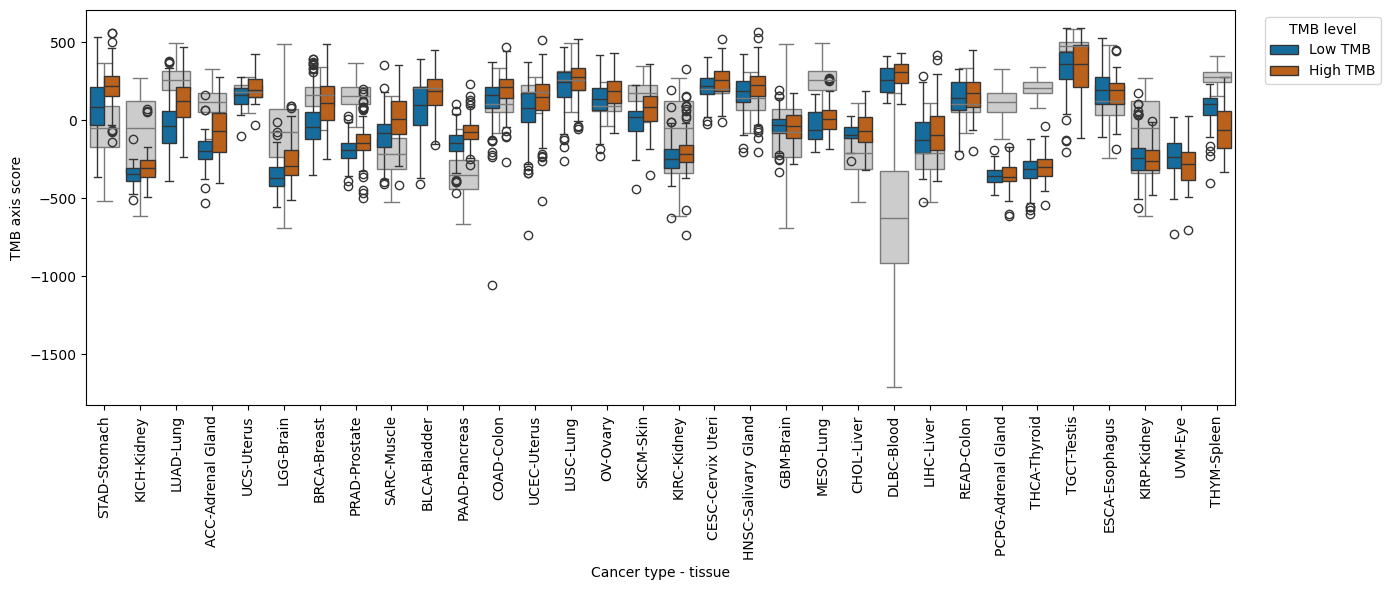

In [35]:
palette_tmb = {"Low TMB": COLORS["low"], "High TMB": COLORS["high"]}

fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    data=gtex_for_plot,
    x="annot",
    y="TMB_axis_score",
    color=COLORS["light_gray"],
    showfliers=False,
    order=annot_order,
    ax=ax
)

sns.boxplot(
    data=df_axis_large_n,
    x="annot",
    y="TMB_axis_score",
    hue="tmb_bin",
    hue_order=["Low TMB", "High TMB"],
    palette=palette_tmb,
    order=annot_order,
    ax=ax
)

for patch in ax.artists:
    patch.set_alpha(0.4)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels, title="TMB level", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=90)
ax.set_ylabel("TMB axis score")
ax.set_xlabel("Cancer type - tissue")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/tumor_vs_matched_normal.pdf", dpi=300)
plt.show()

## Figure 3B: High vs low TMB by cancer type

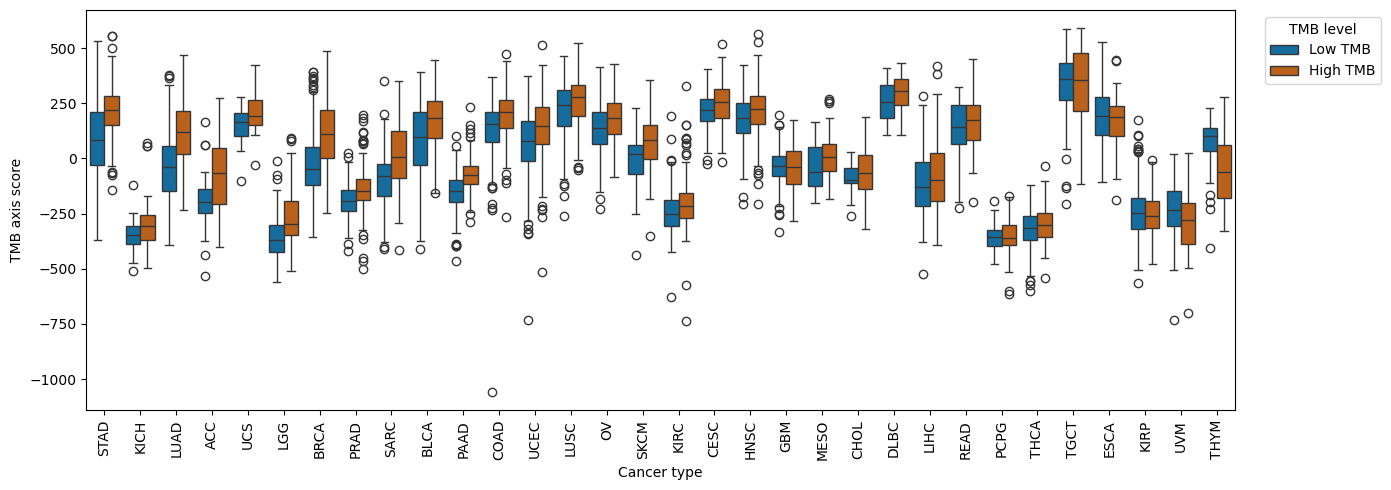

In [36]:
fig, ax = plt.subplots(figsize=(14, 5))

sns.boxplot(
    data=df_axis_large_n,
    x="cancer_type",
    y="TMB_axis_score",
    hue="tmb_bin",
    hue_order=["Low TMB", "High TMB"],
    palette=palette_tmb,
    order=order,
    ax=ax
)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels, title="TMB level", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=90)
ax.set_ylabel("TMB axis score")
ax.set_xlabel("Cancer type")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/tumor_high_low.pdf", dpi=300)
plt.show()

## Figure 3C: Example cancer types (below vs above global median)

In [37]:
global_median = df_axis["TMB_axis_score"].median()

summary = (
    df_axis_large_n
    .groupby(["annot", "tmb_bin"], observed=True)["TMB_axis_score"]
    .median()
    .reset_index()
)
summary_wide = summary.pivot(index="annot", columns="tmb_bin", values="TMB_axis_score").reset_index()
summary_wide.columns.name = None
summary_wide["delta"] = summary_wide["High TMB"] - summary_wide["Low TMB"]

below = summary_wide[
    (summary_wide["Low TMB"] < global_median) & (summary_wide["High TMB"] < global_median)
]
above = summary_wide[
    (summary_wide["Low TMB"] > global_median) & (summary_wide["High TMB"] > global_median)
]

example_below = below.sort_values("delta", ascending=False).iloc[0]
example_above = above.sort_values("delta", ascending=False).iloc[0]
print(example_below["annot"], example_above["annot"])

ACC-Adrenal Gland STAD-Stomach


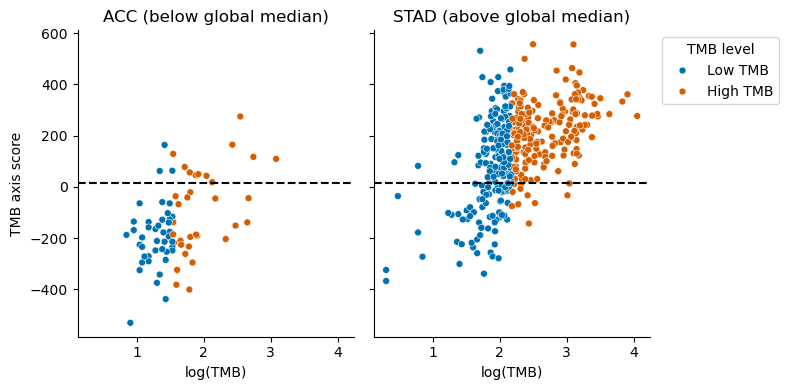

In [38]:
example1 = example_below["annot"]
example2 = example_above["annot"]
type1 = example1.split("-")[0]
type2 = example2.split("-")[0]
subset = df_axis_large_n[df_axis_large_n["annot"].isin([example1, example2])]
title_map = {
    example1: f"{type1} (below global median)",
    example2: f"{type2} (above global median)",
}

g = sns.FacetGrid(subset, col="annot", height=4, sharey=True)
g.map_dataframe(
    sns.scatterplot,
    x="log_mut",
    y="TMB_axis_score",
    hue="tmb_bin",
    hue_order=["Low TMB", "High TMB"],
    palette=palette_tmb,
    s=25,
)
for ax in g.axes.flat:
    current_title = ax.get_title().split(" = ")[-1]
    ax.set_title(title_map.get(current_title, current_title))
    ax.axhline(global_median, linestyle="--", color="black")

g.set_axis_labels("log(TMB)", "TMB axis score")
plt.legend(title="TMB level", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/relative_scale_eg.pdf", dpi=300)
plt.show()

## Figure 3D: TMB axis score z-scored within cancer type

In [39]:
df_axis_z = pd.read_parquet(f"{WORKING_DIR}/axis_sample_scores/within_type_z/tcga_xena/axis_sample_level.parquet")
df_axis_z["tissue_gtex"] = df_axis_z["cancer_type"].map(tcga_to_gtex)
df_axis_z["annot"] = df_axis_z["cancer_type"] + "-" + df_axis_z["tissue_gtex"]
df_axis_z["tmb_bin"] = (
    df_axis_z
    .groupby("cancer_type")["log_mut"]
    .transform(lambda x: pd.qcut(x, q=2, labels=["Low TMB", "High TMB"]))
)

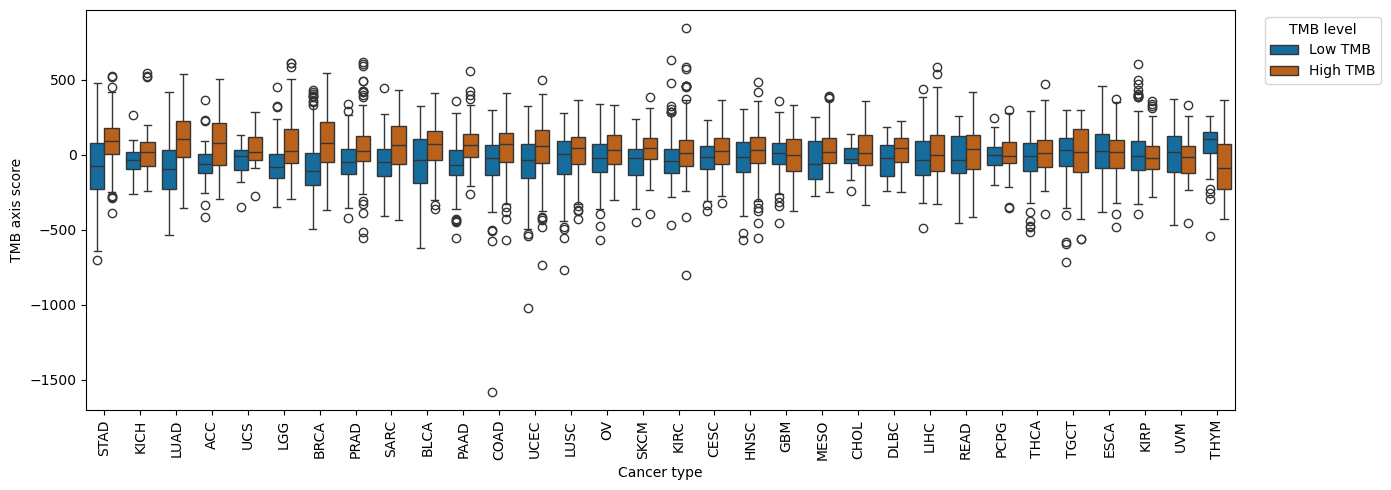

In [42]:
fig, ax = plt.subplots(figsize=(14, 5))

sns.boxplot(
    data=df_axis_z,
    x="cancer_type",
    y="TMB_axis_score",
    hue="tmb_bin",
    hue_order=["Low TMB", "High TMB"],
    palette=palette_tmb,
    order=order,
    # legend=False,
    ax=ax
)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels, title="TMB level", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=90)
ax.set_ylabel("TMB axis score")
ax.set_xlabel("Cancer type")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/results/figures/main/fig3/zscored_within_type.pdf", dpi=300)
plt.show()